First 5 rows of dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset Shape: (150, 4)

Dataset Information:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6

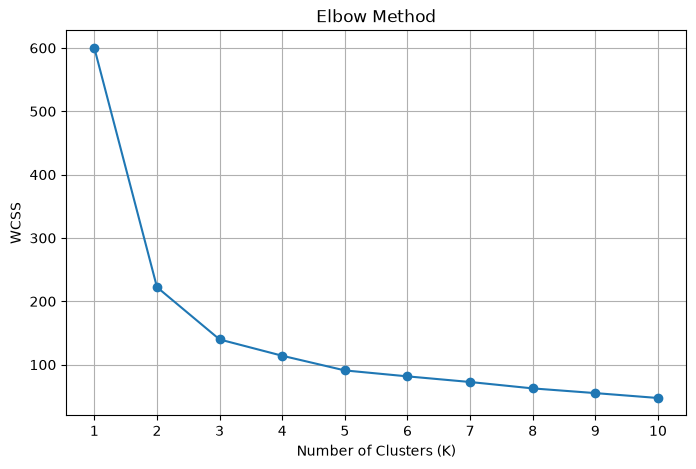


K-Means Cluster Counts:
KMeans_Cluster
0    53
1    50
2    47
Name: count, dtype: int64

K-Means Silhouette Score: 0.4599


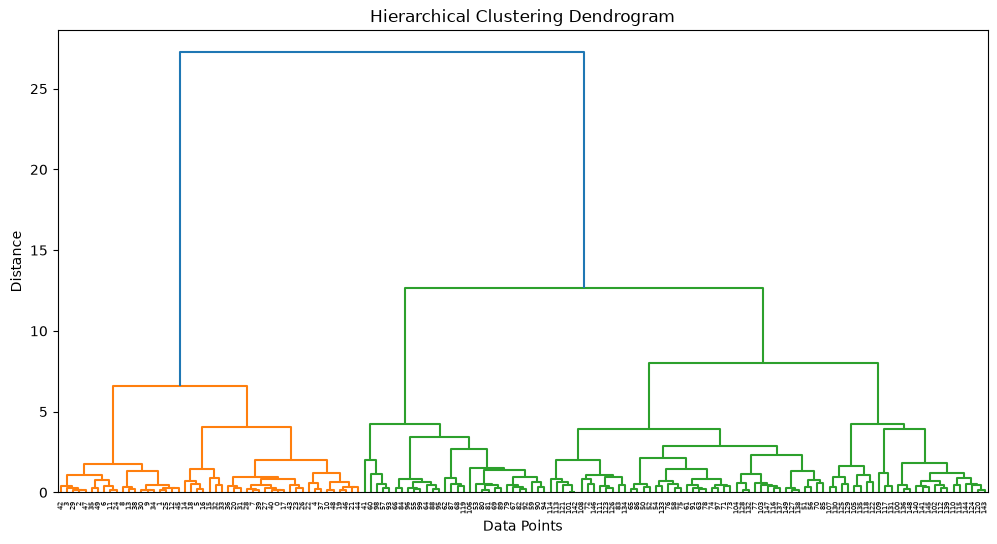


Hierarchical Cluster Counts:
Hierarchical_Cluster
0    71
1    49
2    30
Name: count, dtype: int64

Hierarchical Silhouette Score: 0.4467


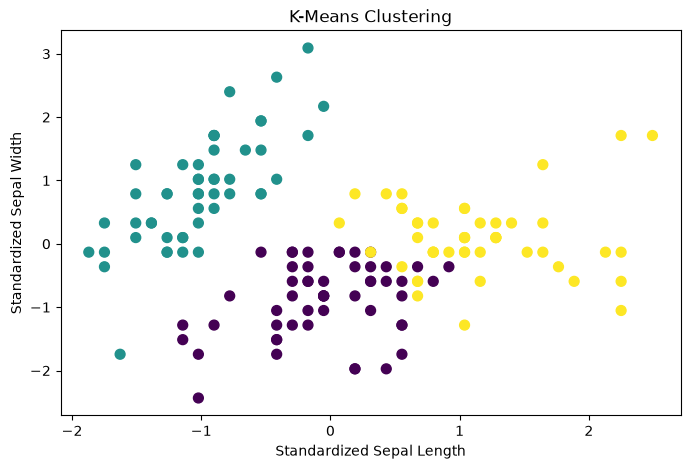

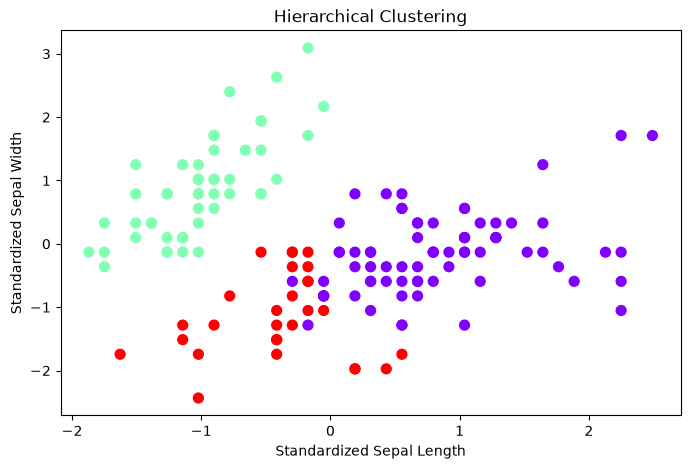


--- CLUSTERING COMPARISON ---
      Method  Number of Clusters  Silhouette Score
     K-Means                   3            0.4599
Hierarchical                   3            0.4467

--- K-MEANS CLUSTER MEANS ---
                sepal length (cm)  sepal width (cm)  petal length (cm)  \
KMeans_Cluster                                                           
0                            5.80              2.67               4.37   
1                            5.01              3.43               1.46   
2                            6.78              3.10               5.51   

                petal width (cm)  
KMeans_Cluster                    
0                           1.41  
1                           0.25  
2                           1.97  

--- HIERARCHICAL CLUSTER MEANS ---
                      sepal length (cm)  sepal width (cm)  petal length (cm)  \
Hierarchical_Cluster                                                           
0                                  6.55    

In [1]:

# Clustering Techniques: K-Means and Hierarchical Clustering

# 1. Import Libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

# 2. Load Dataset
data = load_iris(as_frame=True)
df = data.data

print("First 5 rows of dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nDataset Information:")
print(df.describe())

# 3. Standardize the Data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# 4. Elbow Method to Find Optimal K
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# 5. Apply K-Means Clustering
# Iris commonly forms 3 groups; compare with the Elbow plot.
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

print("\nK-Means Cluster Counts:")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())

print("\nK-Means Silhouette Score:",
      round(silhouette_score(X_scaled, kmeans_labels), 4))

# 6. Create Dendrogram for Hierarchical Clustering
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

# 7. Apply Hierarchical Clustering
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

df_hierarchical = df.copy()
df_hierarchical["Hierarchical_Cluster"] = hierarchical_labels

print("\nHierarchical Cluster Counts:")
print(
    df_hierarchical["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
)

print("\nHierarchical Silhouette Score:",
      round(silhouette_score(X_scaled, hierarchical_labels), 4))

# 8. Visualize K-Means Clusters
plt.figure(figsize=(8, 5))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=50
)
plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Sepal Width")
plt.title("K-Means Clustering")
plt.show()

# 9. Visualize Hierarchical Clusters
plt.figure(figsize=(8, 5))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=hierarchical_labels,
    cmap="rainbow",
    s=50
)
plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Sepal Width")
plt.title("Hierarchical Clustering")
plt.show()

# 10. Compare Both Clustering Techniques
comparison = pd.DataFrame({
    "Method": ["K-Means", "Hierarchical"],
    "Number of Clusters": [
        len(set(kmeans_labels)),
        len(set(hierarchical_labels))
    ],
    "Silhouette Score": [
        silhouette_score(X_scaled, kmeans_labels),
        silhouette_score(X_scaled, hierarchical_labels)
    ]
})

print("\n--- CLUSTERING COMPARISON ---")
print(comparison.round(4).to_string(index=False))

# 11. Analyze Cluster Characteristics
print("\n--- K-MEANS CLUSTER MEANS ---")
print(df_kmeans.groupby("KMeans_Cluster").mean().round(2))

print("\n--- HIERARCHICAL CLUSTER MEANS ---")
print(
    df_hierarchical.groupby("Hierarchical_Cluster")
    .mean()
    .round(2)
)

print("\nPractical completed successfully!")
